# Risk-aware MCTS
#### `four_state_mdp` experiments

In [1]:
import os
import json
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
import seaborn as sns
sns.set_style("dark")

matplotlib.rcParams['text.usetex'] = False
matplotlib.rcParams.update({'font.size': 16})

sns.set_palette("colorblind")

In [2]:
def calculate_erm(dist, beta):
    dist = np.asarray(dist)
    return (1.0 / beta) * np.log((1 / len(dist)) * np.sum(np.exp(beta * dist)))

In [3]:
def erm_ci(samples: np.ndarray, beta: float, num_resamples: int = 25_000):
    # Confidence interval estimation via bootstrap resampling.
    samples = np.asarray(samples)
    resampled = np.random.choice(samples, size=(len(samples), num_resamples), replace=True).T
    erms = (1.0 / beta) * np.log((1 / resampled.shape[1]) * np.sum(np.exp(beta * resampled), axis=1))
    return [np.percentile(erms, 5), np.percentile(erms, 95)]

### Load experiment data

Reads every completed cell for this environment from the sweep's `manifest.json` / `exp_data.json` files (output of `run_experiments.py`).

If the sweep covers several `K_ucb` values, only the "ERM vs. `K_ucb`" plot uses all of them. Every other plot uses the single slice `K_ucb_to_plot`, which is the value closest to `sqrt(2)`, the fixed `K_ucb` used before it was swept.

In [13]:
SWEEP_DIR = 'data/sweep_demo_2026-10-09-15-03-54_seed0'
ENV_NAME = 'four_state_mdp'

with open(os.path.join(SWEEP_DIR, "manifest.json")) as f:
    manifest = json.load(f)

DEFAULT_K_UCB = 0.3 #float(np.sqrt(2))  # K_ucb of sweeps that didn't sweep it (their manifests have no "K_ucb")

# (algo, beta, n_iter, K_ucb, f_vals); n_iter and K_ucb are None for erm-bi, which uses neither
cells = []
for cell_name, meta in manifest["cells"].items():
    if meta["env"] != ENV_NAME or meta["status"] != "done":
        continue
    exp_path = os.path.join(SWEEP_DIR, cell_name, "exp_data.json")
    with open(exp_path) as f:
        raw = json.load(f)
    exp = json.loads(raw) if isinstance(raw, str) else raw

    K_ucb = None if meta["algo"] == "erm-bi" else meta.get("K_ucb", DEFAULT_K_UCB)
    cells.append((meta["algo"], meta["erm_beta"], meta["n_iter"], K_ucb, exp["f_vals"]))

K_ucbs = sorted({c[3] for c in cells if c[3] is not None})
# K_ucb slice used by every plot except "ERM vs. K_ucb": the value closest to sqrt(2), the old fixed K_ucb
K_ucb_to_plot = min(K_ucbs, key=lambda k: abs(k - DEFAULT_K_UCB)) if K_ucbs else None

# algo -> beta -> n_iter -> f_vals, at K_ucb_to_plot   (n_iter is None for erm-bi, which doesn't use it)
data = {}
# algo -> beta -> n_iter -> K_ucb -> f_vals, every K_ucb   (erm-bi: data_k["erm-bi"][beta][None][None])
data_k = {}
for algo, beta, n_iter, K_ucb, f_vals in cells:
    data_k.setdefault(algo, {}).setdefault(beta, {}).setdefault(n_iter, {})[K_ucb] = f_vals
    if K_ucb is None or K_ucb == K_ucb_to_plot:
        data.setdefault(algo, {}).setdefault(beta, {})[n_iter] = f_vals

algos = sorted(data.keys())
betas = [0.01,5,25]#sorted({b for algo_d in data.values() for b in algo_d.keys()})
n_iters = sorted({n for algo_d in data.values() for beta_d in algo_d.values() for n in beta_d.keys() if n is not None})
n_iter_to_plot = n_iters[-1] if n_iters else None  # n_iter slice used by the plots below

print("algos:", algos)
print("betas:", betas)
print("n_iters:", n_iters)
print("n_iter_to_plot:", n_iter_to_plot)
print("K_ucbs:", K_ucbs)
print("K_ucb_to_plot:", K_ucb_to_plot)

algos: ['acc-mcts', 'erm-bi', 'erm-mcts']
betas: [0.01, 5, 25]
n_iters: [100, 500, 1000, 5000]
n_iter_to_plot: 5000
K_ucbs: [0.1, 0.3, 1.4142]
K_ucb_to_plot: 0.3


### Compare ERM's of the distribution of costs obtained by different algorithms (numbers, every beta)

ERM and 5-95% bootstrap CI per algorithm and `beta`, at `ERM_TABLE_N_ITER` / `ERM_TABLE_K_UCB` (default: the plotted slice).

In [14]:
ERM_TABLE_N_ITER = n_iter_to_plot   # n_iter slice (ignored by erm-bi)
ERM_TABLE_K_UCB = K_ucb_to_plot     # K_ucb slice (ignored by erm-bi)
ERM_TABLE_ALGOS = [("erm-bi", "ERM-BI"), ("acc-mcts", "Acc-MCTS"), ("erm-mcts", "ERM-MCTS")]

print(f"{ENV_NAME}: n_iter = {ERM_TABLE_N_ITER}, K_ucb = {ERM_TABLE_K_UCB}")
for beta in betas:
    print(f"\nbeta = {beta}")
    for algo, label in ERM_TABLE_ALGOS:
        if algo == "erm-bi":
            f_vals = data_k.get(algo, {}).get(beta, {}).get(None, {}).get(None)
        else:
            f_vals = data_k.get(algo, {}).get(beta, {}).get(ERM_TABLE_N_ITER, {}).get(ERM_TABLE_K_UCB)
        if f_vals is None:
            continue  # e.g. no erm-bi on binpacking
        f_vals = np.array(f_vals)
        erm_val = calculate_erm(f_vals, beta=beta)
        cis = erm_ci(f_vals, beta=beta)
        print(f"  {label:9s}: {erm_val:.4f} ; CI's: [{cis[0]:.4f}, {cis[1]:.4f}] ; "
              f"CI's (lengths): {erm_val - cis[0]:.4f} {cis[1] - erm_val:.4f} ; N = {len(f_vals)}")

four_state_mdp: n_iter = 5000, K_ucb = 0.3

beta = 0.01
  ERM-BI   : 0.1704 ; CI's: [0.1535, 0.1877] ; CI's (lengths): 0.0169 0.0173 ; N = 500
  Acc-MCTS : 0.1704 ; CI's: [0.1533, 0.1877] ; CI's (lengths): 0.0170 0.0173 ; N = 500
  ERM-MCTS : 0.1704 ; CI's: [0.1534, 0.1877] ; CI's (lengths): 0.0169 0.0173 ; N = 500

beta = 5
  ERM-BI   : 0.2155 ; CI's: [0.2137, 0.2173] ; CI's (lengths): 0.0018 0.0018 ; N = 500
  Acc-MCTS : 0.2424 ; CI's: [0.2194, 0.2690] ; CI's (lengths): 0.0230 0.0266 ; N = 500
  ERM-MCTS : 0.2151 ; CI's: [0.2134, 0.2168] ; CI's (lengths): 0.0017 0.0018 ; N = 500

beta = 25
  ERM-BI   : 0.2188 ; CI's: [0.2178, 0.2197] ; CI's (lengths): 0.0010 0.0010 ; N = 500
  Acc-MCTS : 0.2863 ; CI's: [0.2185, 0.3239] ; CI's (lengths): 0.0678 0.0376 ; N = 500
  ERM-MCTS : 0.2188 ; CI's: [0.2178, 0.2197] ; CI's (lengths): 0.0010 0.0010 ; N = 500


### ERM vs. planning budget (`n_iter`), one panel per (`beta`, `K_ucb`)

Compares the sampling-based planners (`erm-mcts`, `acc-mcts`) as the per-timestep iteration budget grows. Rows are `beta`, columns are the swept `K_ucb`. Bands are 5–95% bootstrap intervals. `erm-bi`, the exact oracle, doesn't depend on `n_iter` or `K_ucb` and is drawn as a single black point with its 5–95% bootstrap interval at the largest `n_iter`, when available.

As in the "ERM vs. `K_ucb`" plot, the same `K_ucb` doesn't mean the same amount of exploration for the two algorithms (ERM units for `erm-mcts`, `exp(beta * cost)` units for `acc-mcts`).

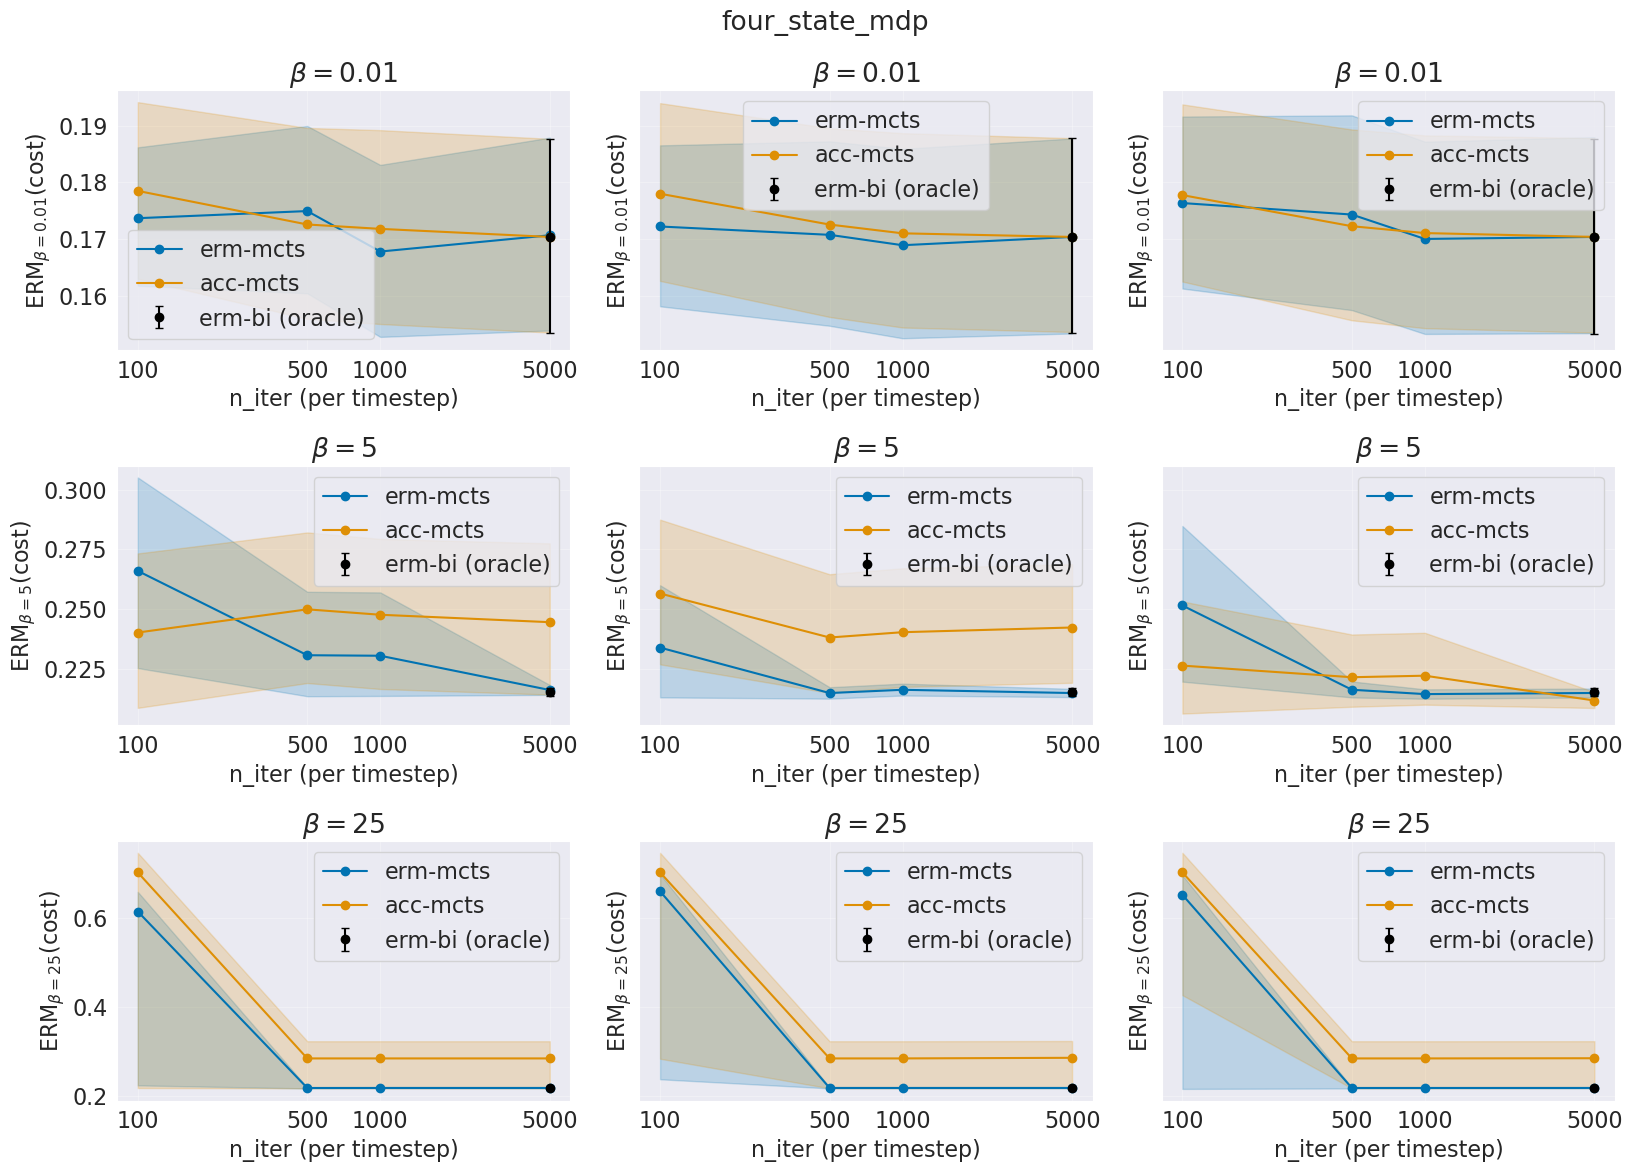

In [15]:
budget_algos = ["erm-mcts", "acc-mcts"]
budget_colors = {algo: sns.color_palette()[i] for i, algo in enumerate(budget_algos)}  # same color per algo in every plot
budget_K_ucbs = K_ucbs if K_ucbs else [None]


def plot_erm_vs_budget(ax, beta, K_ucb):
    """Draws ERM_beta vs. n_iter for erm-mcts and acc-mcts at K_ucb, plus the erm-bi point if available."""
    for algo in budget_algos:
        beta_d = data_k.get(algo, {}).get(beta, {})
        xs = sorted(n for n in beta_d if K_ucb in beta_d[n])
        if not xs:
            continue
        ys = [calculate_erm(beta_d[n][K_ucb], beta=beta) for n in xs]
        cis = np.array([erm_ci(beta_d[n][K_ucb], beta=beta) for n in xs])
        ax.plot(xs, ys, marker="o", color=budget_colors[algo], label=algo)
        ax.fill_between(xs, cis[:, 0], cis[:, 1], color=budget_colors[algo], alpha=0.2)

    bi_f_vals = data_k.get("erm-bi", {}).get(beta, {}).get(None, {}).get(None)
    if bi_f_vals is not None:
        # Oracle: no n_iter or K_ucb dependence; one point with its bootstrap interval at the largest n_iter.
        bi_erm = calculate_erm(bi_f_vals, beta=beta)
        bi_ci = erm_ci(bi_f_vals, beta=beta)
        ax.errorbar(n_iters[-1], bi_erm, yerr=[[bi_erm - bi_ci[0]], [bi_ci[1] - bi_erm]],
                    fmt="o", capsize=3, color="black", label="erm-bi (oracle)")

    ax.set_xlabel("n_iter (per timestep)")
    ax.set_ylabel(fr"ERM$_{{\beta={beta}}}$(cost)")
    ax.set_xscale("log")
    ax.set_xticks(n_iters)
    ax.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
    ax.get_xaxis().set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax.grid(True, alpha=0.3)
    ax.legend()


fig, axes = plt.subplots(len(betas), len(budget_K_ucbs), figsize=(5.5 * len(budget_K_ucbs), 4.0 * len(betas)),
                         squeeze=False, sharey="row")
for row, beta in zip(axes, betas):
    for ax, K_ucb in zip(row, budget_K_ucbs):
        plot_erm_vs_budget(ax, beta, K_ucb)
        ax.set_title(fr"$\beta={beta}$" if K_ucb is not None else fr"$\beta={beta}$")
fig.suptitle(ENV_NAME)
fig.tight_layout()
plt.show()

#### Save one ERM vs. planning budget figure per (`beta`, `K_ucb`)

Writes each panel above as its own PDF to `FIGS_DIR`, named `<env>_erm_vs_niter_beta_<beta>_K_<K_ucb>.pdf`, so a single one per `beta` can go in the paper. The figures have no title (`beta` and `K_ucb` are in the file name); set `SAVE_TITLES = True` to add one.

In [16]:
FIGS_DIR = "figs"
SAVE_TITLES = True

os.makedirs(FIGS_DIR, exist_ok=True)
for beta in betas:
    for K_ucb in budget_K_ucbs:
        fig, ax = plt.subplots(figsize=(5.5, 4.0))
        plot_erm_vs_budget(ax, beta, K_ucb)
        if SAVE_TITLES:
            ax.set_title(fr"$\beta={beta}$, $K_{{ucb}}={K_ucb:g}$" if K_ucb is not None else fr"$\beta={beta}$")
        k_tag = f"_K_{K_ucb:g}" if K_ucb is not None else ""
        path = os.path.join(FIGS_DIR, f"{ENV_NAME}_erm_vs_niter_beta_{beta:g}{k_tag}.pdf")
        fig.savefig(path, bbox_inches="tight", pad_inches=0)
        plt.close(fig)
        print("saved", path)

saved figs/four_state_mdp_erm_vs_niter_beta_0.01_K_0.1.pdf
saved figs/four_state_mdp_erm_vs_niter_beta_0.01_K_0.3.pdf
saved figs/four_state_mdp_erm_vs_niter_beta_0.01_K_1.4142.pdf
saved figs/four_state_mdp_erm_vs_niter_beta_5_K_0.1.pdf
saved figs/four_state_mdp_erm_vs_niter_beta_5_K_0.3.pdf
saved figs/four_state_mdp_erm_vs_niter_beta_5_K_1.4142.pdf
saved figs/four_state_mdp_erm_vs_niter_beta_25_K_0.1.pdf
saved figs/four_state_mdp_erm_vs_niter_beta_25_K_0.3.pdf
saved figs/four_state_mdp_erm_vs_niter_beta_25_K_1.4142.pdf


### Distribution of costs, per algorithm

Histogram of the (discounted) cumulative cost `f_vals` across episodes, one panel per algorithm, overlaying the `beta` values in `COST_BETAS` at the fixed `n_iter` chosen above.

Set `COST_BETAS` to a subset of the swept betas to plot only those (`None` = all). Each `beta` keeps the same color whatever the subset. With `SAVE_COST_FIGS = True`, the histogram and the boxplot below are also written as PDFs to `FIGS_DIR`, named `<env>_cost_{hist,boxplot}_niter_<n_iter>_K_<K_ucb>_betas_<b1>_<b2>....pdf`.

In [17]:
COST_BETAS = [0.01,5,25]  # betas shown in the histogram and the boxplot, e.g. [0.01, 5]; None = every beta in the sweep
HIST_YMAX = None#15  # cap on the histogram y axis (density), e.g. 5, so tall peaks don't squash the rest; None = auto
SAVE_COST_FIGS = True  # also write both figures as PDFs to FIGS_DIR

cost_betas = betas if COST_BETAS is None else [b for b in betas if b in COST_BETAS]
missing = [b for b in (COST_BETAS or []) if b not in betas]
if missing:
    print(f"betas {missing} are not in {SWEEP_DIR} (available: {betas}), skipping them")
cost_colors = {b: sns.color_palette()[betas.index(b) % 10] for b in betas}  # same color per beta in every subset

k_tag = f"_K_{K_ucb_to_plot:g}" if K_ucb_to_plot is not None else ""
cost_fig_tag = f"niter_{n_iter_to_plot}{k_tag}_betas_" + "_".join(f"{b:g}" for b in cost_betas)
os.makedirs(FIGS_DIR, exist_ok=True)
print("cost_betas:", cost_betas)

cost_betas: [0.01, 5, 25]


saved figs/four_state_mdp_cost_hist_niter_5000_K_0.3_betas_0.01_5_25.pdf


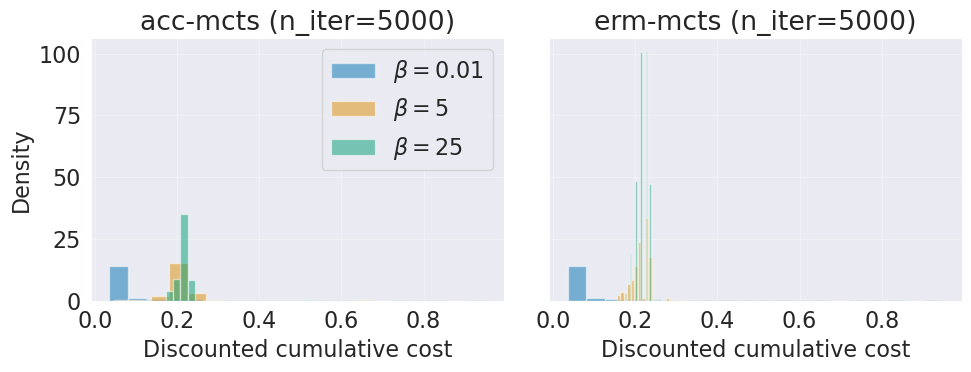

In [20]:
algos=["acc-mcts", "erm-mcts"]
SAVE_TITLES = False

fig, axes = plt.subplots(1, len(algos), figsize=(5.0 * len(algos), 4.0), sharey=True)
if len(algos) == 1:
    axes = [axes]

for ax, algo in zip(axes, algos):
    algo_d = data[algo]
    for beta in cost_betas:
        if beta not in algo_d:
            continue
        key = None if algo == "erm-bi" else n_iter_to_plot
        if key not in algo_d[beta]:
            continue
        ax.hist(algo_d[beta][key], density=True, bins=20, alpha=0.5, color=cost_colors[beta], label=fr"$\beta={beta}$")
    ax.set_title(algo if algo == "erm-bi" else f"{algo} (n_iter={n_iter_to_plot})")
    ax.set_xlabel("Discounted cumulative cost")
    ax.grid(True, alpha=0.3)
if HIST_YMAX is not None:
    axes[0].set_ylim(top=HIST_YMAX)  # sharey, so this caps every panel
axes[0].set_ylabel("Density")
axes[0].legend()
fig.tight_layout()
if SAVE_COST_FIGS:
    titles = [ax.get_title() for ax in axes]
    if not SAVE_TITLES:
        for ax in axes:
            ax.set_title("")
    path = os.path.join(FIGS_DIR, f"{ENV_NAME}_cost_hist_{cost_fig_tag}.pdf")
    fig.savefig(path, bbox_inches="tight", pad_inches=0)
    for ax, title in zip(axes, titles):
        ax.set_title(title)
    print("saved", path)
plt.show()

### Boxplot comparison across algorithms and betas (fixed `n_iter`)

saved figs/four_state_mdp_cost_boxplot_niter_5000_K_0.3_betas_0.01_5_25.pdf


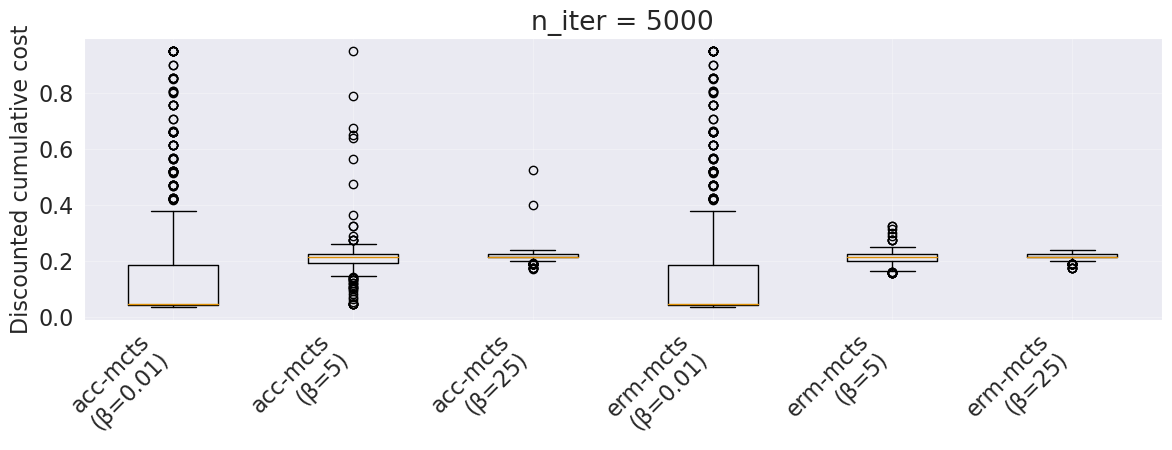

In [21]:
fig, ax = plt.subplots(figsize=(2.0 * len(algos) * len(cost_betas), 4.5))

data_to_plot, labels = [], []
for algo in algos:
    algo_d = data[algo]
    for beta in cost_betas:
        if beta not in algo_d:
            continue
        key = None if algo == "erm-bi" else n_iter_to_plot
        if key not in algo_d[beta]:
            continue
        data_to_plot.append(algo_d[beta][key])
        labels.append(f"{algo}\n(β={beta})")

ax.boxplot(data_to_plot, labels=labels)
ax.set_ylabel("Discounted cumulative cost")
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45, ha="right")
fig.tight_layout()
if SAVE_COST_FIGS:
    if SAVE_TITLES:
        ax.set_title(f"n_iter = {n_iter_to_plot}")
    path = os.path.join(FIGS_DIR, f"{ENV_NAME}_cost_boxplot_{cost_fig_tag}.pdf")
    fig.savefig(path, bbox_inches="tight", pad_inches=0)
    print("saved", path)
ax.set_title(f"n_iter = {n_iter_to_plot}")
plt.show()